# Axial buckling of integrally stringer-stiffened cylinders: Card and Jones (1966)

Card and Jones [1] tested in axial compression twelve cylinders with
longitudinal stiffeners, in pairs with the stiffeners outside (external) or
inside (internal) the skin, and compared the buckling loads with a theory of
eccentrically stiffened cylinders with the stiffeners averaged ("smeared")
over the skin, a membrane pre-buckling state, and simply supported or
clamped ends. Their cylinders 1 to 4 have integral rectangular (blade)
stiffeners machined from aluminium plates: cylinders 1 (external) and 2
(internal) are 38.00 in long, cylinders 3 (external) and 4 (internal) 23.75
in long. The externally stiffened cylinders carried more than twice the
load of the internally stiffened ones ([1], summary).

Here the four cylinders are modelled with discrete stringers:

- the skin with the BFSC cylinder element of Sanders-type kinematics,
  `BFSCCylinderSanders`;
- each stringer with the BFSC plate element `BFSCPlate2D` of
  [bfscplate2d](https://github.com/saullocastro/bfscplate2d), in the
  plane $(x, r)$ of the stringer, from the middle surface of the skin to the
  tip, its root tied to the skin.

As in the notebook of the vibration tests of Sewall and Naumann, the model
is one stringer pitch with cyclic symmetry, given by the module
`blade_cylinder_sector.py` next to this notebook: one linear buckling problem
$(\boldsymbol{K}_{C0} + \lambda \boldsymbol{K}_G)\boldsymbol{\phi} =
\boldsymbol{0}$ per circumferential wave number $n$. Besides `bfsccylinder`,
it needs `bfscplate2d`, `composites`, SciPy and Matplotlib. The
smeared-stiffener theory of [1], that of Block, Card and Mikulas [2], is
computed with the module `smeared_stiffened_cylinder.py`, also next to this
notebook.

**References**

[1] Card, M. F.; Jones, R. M., "Experimental and theoretical results for
buckling of eccentrically stiffened cylinders", NASA TN D-3639, October
1966. https://ntrs.nasa.gov/citations/19660027866

[2] Block, D. L.; Card, M. F.; Mikulas, M. M., Jr., "Buckling of
eccentrically stiffened orthotropic cylinders", NASA TN D-2960, August
1965. https://ntrs.nasa.gov/citations/19650021133

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt

from bfsccylinder.version import __version__ as bfsccylinder_version
from bfscplate2d.version import __version__ as bfscplate2d_version
from blade_cylinder_sector import (BladeCylinderSector, buckling_membrane,
                                   prebuckling_clamped, buckling_prebuckled,
                                   axial_nodes, normalize_phase, W)
from smeared_stiffened_cylinder import (blade_properties, buckling_ss,
                                        buckling_ritz, axial_half_waves)

print('bfsccylinder', bfsccylinder_version)
print('bfscplate2d', bfscplate2d_version)

bfsccylinder 0.7.1
bfscplate2d 0.5.0


## Cylinders, geometry and material

Table I(a) of [1] (report page 7) gives, for each cylinder, the skin
thickness $t$ (the average of many micrometer measurements, individual
values scattering by ±8 %), the length $L$, the radius $R$ of the middle
surface, the area $A_t$ of the stiffened cross-section, the experimental
buckling load $\bar{P}_e$ and stress $\bar{\sigma}_e$, the number of
circumferential waves $n_e$ of the buckled test cylinder, and the axial
force per unit circumference at buckling, $\bar{N}_e$ from the test,
$\bar{N}_c$ from the theory with clamped ends and $\bar{N}_s$ from the
theory with simply supported ends. Its footnote gives $E = 10.5 \times 10^3$
ksi and $\mu = 0.32$ (2024-T351 aluminium alloy). Figure 2(b) of [1] (report
page 6) gives the stiffener: 0.097 in wide, at a spacing of 1.00 in, 0.33 in
from the surface of the skin opposite to the stiffener to the tip of the
stiffener, with fillets dimensioned 0.03 in (taken here as their radius);
the spacing gives 60 stiffeners,
$2 \pi \times 9.55/1.00 = 60.0$.

In [2]:
# Table I(a) of [1], report page 7; t, L, R in in, A_t in in^2, P_e in lbf,
# sigma_e in psi, N in lb/in (see below)
cylinders = {
    1: dict(side='external', t=0.0283, L=38.00, R=9.55, At=3.69, Pe=112.6e3,
            sigma_e=30.5e3, ne=6, Ne=1877., Nc=2036., Ns=1145.),
    2: dict(side='internal', t=0.0277, L=38.00, R=9.55, At=3.72, Pe=48.0e3,
            sigma_e=12.9e3, ne=6, Ne=800., Nc=997., Ns=687.),
    3: dict(side='external', t=0.0275, L=23.75, R=9.55, At=3.70, Pe=127.2e3,
            sigma_e=34.4e3, ne=7, Ne=2120., Nc=2595., Ns=1326.),
    4: dict(side='internal', t=0.0280, L=23.75, R=9.55, At=3.63, Pe=58.0e3,
            sigma_e=16.0e3, ne=6, Ne=965., Nc=1226., Ns=722.),
}
# Table I(b) of [1], report page 7: N_e, N_c, N_s as printed, header MN/m
si = {1: (329, 357, 200), 2: (140, 175, 120), 3: (371, 454, 232),
      4: (169, 215, 127)}
E = 10.5e6  # psi, footnote of Table I
mu = 0.32
nstringers = 60
bs = 0.097  # in, Figure 2(b)
depth = 0.33  # in, from the skin surface opposite to the stiffener
r_fillet = 0.03  # in

lbf = 4.4482216  # N
inch = 0.0254  # m
print('E = %.1f GPa' % (E*lbf/inch**2/1e9))
print('cyl.  P_e/(2 pi R)  N_e    N_e in kN/m  Table I(b)  '
      'P_e/A_t (sigma_e)')
for k, c in cylinders.items():
    print('%3d  %8.0f lb/in  %5.0f  %8.1f     %5d       %.1f ksi (%.1f)'
          % (k, c['Pe']/(2*np.pi*c['R']), c['Ne'],
             c['Ne']*lbf/inch/1e3, si[k][0], c['Pe']/c['At']/1e3,
             c['sigma_e']/1e3))

E = 72.4 GPa
cyl.  P_e/(2 pi R)  N_e    N_e in kN/m  Table I(b)  P_e/A_t (sigma_e)
  1      1877 lb/in   1877     328.7       329       30.5 ksi (30.5)
  2       800 lb/in    800     140.1       140       12.9 ksi (12.9)
  3      2120 lb/in   2120     371.3       371       34.4 ksi (34.4)
  4       967 lb/in    965     169.0       169       16.0 ksi (16.0)


Two remarks on Table I of [1]:

- the columns $\bar{N}_e$, $\bar{N}_c$ and $\bar{N}_s$ of Table I(a) are
  headed kips/in., but their values are in lb/in: $\bar{P}_e/(2 \pi R)$
  gives $\bar{N}_e$ in lb/in, as printed above; likewise the values of Table
  I(b), headed MN/m, are the values of Table I(a) converted to kN/m, and
  $\bar{\sigma}_e = \bar{P}_e/A_t$;
- the area of the cross-section from the dimensions of Figure 2(b) and the
  thickness $t$, computed below, is 4.7 % to 7.4 % smaller than $A_t$; the two
  butt joints of each cylinder, with two doubler plates 0.70 in wide and
  0.020 in thick each ([1], report page 5), add only about 0.06 in$^2$. [1]
  states that the dimensions of Table I of the integral cylinders "were
  obtained by careful measurement", but gives no measured stiffener
  dimensions besides Figure 2(b). The theoretical values $\bar{N}_c$ and
  $\bar{N}_s$ of [1] were computed with the section of Figure 2(b): the
  smeared-stiffener theory computed below from these dimensions reproduces
  them within 1 %. The main model follows Figure 2(b) and Table I; models
  whose section has the area $A_t$ are compared with it in the section
  "Cross-section adjusted to $A_t$".

The plate of a stringer goes from the middle surface of the skin to the tip,
of height $H_s = 0.33 - t/2$ and thickness $b_s = 0.097$ in; the fillets
are not modelled.

In [3]:
for k, c in cylinders.items():
    Hs = depth - c['t']/2
    fillets = nstringers*2*(1 - np.pi/4)*r_fillet**2
    drawn = 2*np.pi*c['R']*c['t'] + nstringers*bs*(depth - c['t']) + fillets
    model_area = 2*np.pi*c['R']*c['t'] + nstringers*bs*Hs
    print('cylinder %d: H_s = %.4f in; area from Figure 2(b) %.3f in^2 '
          '(%+.1f %% of A_t = %.2f), model %.3f in^2'
          % (k, Hs, drawn, 100*(drawn/c['At'] - 1), c['At'], model_area))

cylinder 1: H_s = 0.3159 in; area from Figure 2(b) 3.477 in^2 (-5.8 % of A_t = 3.69), model 3.536 in^2
cylinder 2: H_s = 0.3162 in; area from Figure 2(b) 3.445 in^2 (-7.4 % of A_t = 3.72), model 3.502 in^2
cylinder 3: H_s = 0.3163 in; area from Figure 2(b) 3.434 in^2 (-7.2 % of A_t = 3.70), model 3.491 in^2
cylinder 4: H_s = 0.3160 in; area from Figure 2(b) 3.461 in^2 (-4.7 % of A_t = 3.63), model 3.519 in^2


## Analyses

The buckling problems are solved for each harmonic $n = 0, 1, \ldots, 30$
of the sector of one stringer pitch: the modes of the whole cylinder with
$n$ circumferential waves, and with $n \pm 60 j$ waves coupled to them by
the discrete stringers, $n = 30$ including the local buckling of the skin
between the stringers with one half-wave per bay. The number of axial
half-waves $m$ of a mode is one more than the number of sign changes along
$x$ of the normal displacement $w$ of the skin. The critical load is given
as the average axial force per unit circumference $\bar{N} = \lambda
P/(2\pi R)$, as in [1].

Three analyses:

- **membrane, clamped**: the pre-buckling state of the theory of [1], a
  uniform axial strain $\epsilon$ without hoop stress, $N_{xx} = E t
  \epsilon$ in the skin and $E b_s \epsilon$ in the stringer, with the
  clamped ends of the theory, $u = v = w = w_{,x} = 0$ ([1], report page
  10), and the end edges of the stringers clamped; compared with
  $\bar{N}_c$. The geometric stiffness of the stringer includes the terms
  of its radial (in-plane) displacement, see `KG_inplane()` in
  `blade_cylinder_sector.py`: without them the axial force of the stringers
  would not act on the radial displacement of the stringers, which is the
  normal displacement $w$ of the skin;
- **membrane, simply supported**: the same pre-buckling state with the
  simply supported ends of the theory, $N_x = v = w = M_x = 0$ ([1], report
  page 9), i.e. $v = w = 0$ and $u$, $w_{,x}$ free, and $V = W = 0$ along
  the end edges of the stringers; compared with $\bar{N}_s$;
- **linear pre-buckling, clamped**: the tests idealized. The ends of the
  cylinders were potted, ground flat and parallel, and loaded by the platens
  of the testing machine, with aluminium bulkheads keeping them circular
  ([1], report page 6): the end $x = 0$ is clamped and the end $x = L$ is
  clamped with the prescribed axial displacement $u = U = -\delta$ of the
  skin and of the stringer. The axisymmetric pre-buckling state, with the
  radial displacement restrained at the ends, and the force $P$, the sum of
  the end reactions, come from a linear static analysis of the harmonic $n
  = 0$; compared with the test value $\bar{N}_e$.

In the three analyses the derivatives along an end edge of its constrained
displacements are constrained as well, `BladeCylinderSector.constrained()`
in `blade_cylinder_sector.py`: along the ends of the skin $v_{,y} = w_{,y} =
0$, and with clamped ends also $u_{,y} = w_{,xy} = 0$; along the end edges
of the stringers, whose edge direction is $Y$, $V_{,Y} = W_{,Y} = 0$, and
with clamped ends also $U_{,Y} = W_{,XY} = 0$.

In [4]:
def build(k, nx, nbay, nh, b=bs, d=depth):
    # b: stiffener width; d: depth from the skin surface opposite to the
    # stiffener to the tip
    c = cylinders[k]
    return BladeCylinderSector(R=c['R'], L=c['L'], h=c['t'], E=E, nu=mu,
                               rho=0., nstringers=nstringers, nx=nx,
                               nbay=nbay, bs=b, Hs=d - c['t']/2,
                               side=c['side'], nh=nh)


def scan(k, mesh, analysis, ns=range(0, 31), num=2, **section):
    # lowest critical load and mode of each harmonic n
    model = build(k, *mesh, **section)
    if analysis == 'linear':
        u0, P = prebuckling_clamped(model)
    out = {}
    for n in ns:
        if analysis == 'linear':
            N, X = buckling_prebuckled(model, u0, P, n, k=num)
        else:
            N, X = buckling_membrane(model, analysis, n, k=num)
        out[n] = (N[0], axial_nodes(model, X[:, 0]) + 1, X[:, 0])
    return model, out


def lowest(out):
    n = min(out, key=lambda n: out[n][0])
    return n, out[n]

## Mesh convergence

The three analyses of the four cylinders with three meshes
`(nx, nbay, nh)`: `nx` nodes along $x$, `nbay` skin elements across the
stringer pitch and `nh` stringer elements along the height. The table gives
the lowest critical load over the harmonics $n = 3$ to $12$, which contain
the lowest modes, its $(m, n)$ and the change from the previous mesh.

In [5]:
meshes = {23.75: [(17, 2, 2), (25, 4, 3), (37, 6, 4)],
          38.00: [(25, 2, 2), (37, 4, 3), (55, 6, 4)]}
t0 = time.time()
print('cyl.  analysis  mesh          dofs   N_cr (lb/in)  (m, n)   change')
for k, c in cylinders.items():
    for analysis in ['CC', 'SS', 'linear']:
        prev = None
        for mesh in meshes[c['L']]:
            model, out = scan(k, mesh, analysis, ns=range(3, 13))
            n, (N, m, _) = lowest(out)
            change = '' if prev is None else '%+.2f %%' % (100*(N/prev - 1))
            print('%3d   %-8s  %-12s %5d   %8.0f      (%d, %2d)  %s'
                  % (k, analysis, mesh, model.Nr, N, m, n, change))
            prev = N
print('%.0f s' % (time.time() - t0))

cyl.  analysis  mesh          dofs   N_cr (lb/in)  (m, n)   change


  1   CC        (25, 2, 2)    1050       2052      (1,  7)  


  1   CC        (37, 4, 3)    2664       2039      (1,  7)  -0.59 %


  1   CC        (55, 6, 4)    5610       2035      (1,  7)  -0.24 %


  1   SS        (25, 2, 2)    1050       1153      (1,  6)  


  1   SS        (37, 4, 3)    2664       1147      (1,  6)  -0.56 %


... (27 outputs left out)

  4   SS        (37, 6, 4)    3774        723      (1,  6)  -0.40 %


  4   linear    (17, 2, 2)     714       1256      (1,  7)  


  4   linear    (25, 4, 3)    1800       1239      (1,  7)  -1.38 %


  4   linear    (37, 6, 4)    3774       1232      (1,  7)  -0.57 %
279 s


The lowest critical loads of the three analyses change by less than 1 %
between the two finest meshes (see the table), which are used below.

## Local buckling of the skin between the stiffeners

The harmonics also contain local modes of the skin between the stiffeners,
with about one half-wave per bay around the circumference and short
half-waves along the length; they need at least six skin elements across
a bay. Below, the harmonics $n = 0$ (all bays in phase), $15$ and $30$
(adjacent bays in opposite phase) of the membrane clamped analysis with
`nbay = 6` and 1.5 and 3 nodes per inch along $x$ (for the internal
stiffeners the lowest mode of $n = 15$ is a general mode, the local one
being higher); [1]
(report pages 5 and 8) designed the cylinders "to preclude local buckling"
and the strain data "indicate no local buckling of the cylinders prior to
general buckling".

In [6]:
t0 = time.time()
local = {}
print('cyl.  nodes/in  mesh            dofs   N_cr (lb/in), (m) for n = 0, 15, '
      '30                 L/m (in)')
for k, c in cylinders.items():
    for per_inch in [1.5, 3]:
        mesh = (int(round(per_inch*c['L'])) + 1, 6, 4)
        model = build(k, *mesh)
        row = []
        for n in [0, 15, 30]:
            N, X = buckling_membrane(model, 'CC', n, k=2)
            m = axial_nodes(model, X[:, 0]) + 1
            local[(k, n)] = (model, N[0], m, X[:, 0])
            row.append('%6.0f (%2d)' % (N[0], m))
        print('%3d   %5.1f     %-14s %6d   %s    %.2f'
              % (k, per_inch, mesh, model.Nr, '  '.join(row), c['L']/m))
print('%.0f s' % (time.time() - t0))

cyl.  nodes/in  mesh            dofs   N_cr (lb/in), (m) for n = 0, 15, 30                 L/m (in)


  1     1.5     (58, 6, 4)       5916     3377 (56)    3295 (56)    3219 (56)    0.68


  1     3.0     (115, 6, 4)     11730     3357 (59)    3286 (57)    3214 (56)    0.68


  2     1.5     (58, 6, 4)       5916     3238 (56)    2753 ( 4)    3108 (56)    0.68


  2     3.0     (115, 6, 4)     11730     3222 (59)    2746 ( 4)    3103 (56)    0.68


  3     1.5     (37, 6, 4)       3774     3162 (35)    3087 (35)    3017 (35)    0.68


  3     3.0     (72, 6, 4)       7344     3146 (37)    3080 (36)    3012 (35)    0.68


  4     1.5     (37, 6, 4)       3774     3317 (35)    3047 ( 3)    3187 (35)    0.68


  4     3.0     (72, 6, 4)       7344     3304 (37)    3037 ( 3)    3182 (35)    0.68
106 s


The local critical loads change by less than 1 % between the two meshes,
and they are above the lowest general-instability loads of the next section
(by about 16 % for cylinder 3, much more for the others), in agreement with
the design and the strain data of [1].

## Critical loads

The three analyses of the four cylinders with the finest meshes, the lowest
critical load of each harmonic $n$:

883 s


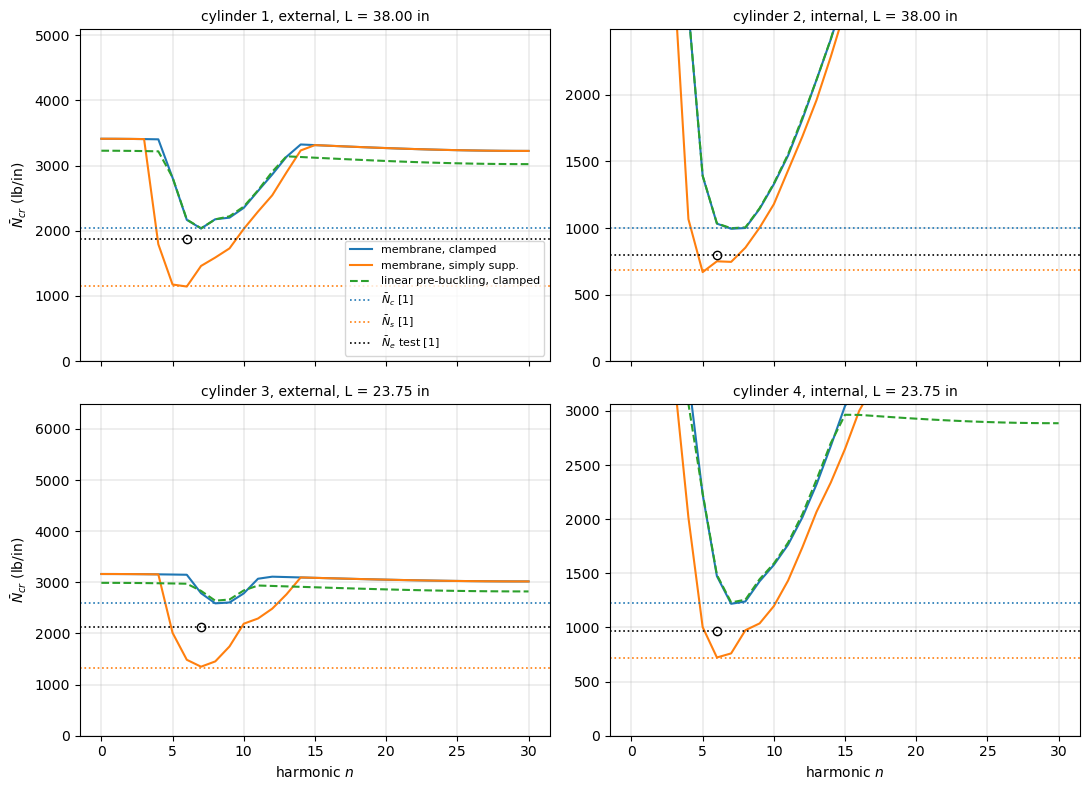

In [7]:
results = {}
t0 = time.time()
for k, c in cylinders.items():
    mesh = meshes[c['L']][-1]
    for analysis in ['CC', 'SS', 'linear']:
        results[(k, analysis)] = scan(k, mesh, analysis)
print('%.0f s' % (time.time() - t0))

names = {'CC': 'membrane, clamped', 'SS': 'membrane, simply supp.',
         'linear': 'linear pre-buckling, clamped'}
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for ax, (k, c) in zip(axes.ravel(), cylinders.items()):
    for analysis, style in [('CC', 'C0-'), ('SS', 'C1-'),
                            ('linear', 'C2--')]:
        out = results[(k, analysis)][1]
        ns = sorted(out)
        ax.plot(ns, [out[n][0] for n in ns], style, label=names[analysis])
    for key, style, label in [('Nc', 'C0:', r'$\bar{N}_c$ [1]'),
                              ('Ns', 'C1:', r'$\bar{N}_s$ [1]'),
                              ('Ne', 'k:', r'$\bar{N}_e$ test [1]')]:
        ax.axhline(c[key], ls=':', color=style[:-1], lw=1.2, label=label)
    ax.plot([c['ne']], [c['Ne']], 'ko', mfc='none')
    ax.set_ylim(0, 2.5*c['Nc'])
    ax.set_title('cylinder %d, %s, L = %.2f in' % (k, c['side'], c['L']),
                 fontsize=10)
    ax.grid(True, lw=0.3)
for ax in axes[1]:
    ax.set_xlabel('harmonic $n$')
for ax in axes[:, 0]:
    ax.set_ylabel(r'$\bar{N}_{cr}$ (lb/in)')
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Comparison with the theory and the tests of Card and Jones

The relative difference is (FE − [1])/[1].

In [8]:
print('cyl.  side      analysis                      FE (lb/in) (m, n)    '
      '[1] (lb/in)            diff')
for k, c in cylinders.items():
    for analysis, key, label in [('CC', 'Nc', 'N_c, theory'),
                                 ('SS', 'Ns', 'N_s, theory'),
                                 ('linear', 'Ne', 'N_e, test')]:
        n, (N, m, _) = lowest(results[(k, analysis)][1])
        print('%3d   %-8s  %-29s %7.0f   (%d, %2d)   %5.0f %-14s %+6.1f %%'
              % (k, c['side'], names[analysis], N, m, n, c[key], label,
                 100*(N/c[key] - 1)))

print('\nTest wave numbers n_e and the linear pre-buckling analysis:')
print('cyl.  n_e  N_cr at n_e (lb/in)  lowest N_cr (n)   N_e (lb/in)  '
      'N_e/N_cr(lowest)')
for k, c in cylinders.items():
    out = results[(k, 'linear')][1]
    n, (N, m, _) = lowest(out)
    print('%3d   %3d   %10.0f           %7.0f (%2d)      %6.0f       %.2f'
          % (k, c['ne'], out[c['ne']][0], N, n, c['Ne'], c['Ne']/N))

print('\nExternal over internal stiffeners, ratio of the lowest loads:')
for pair in [(1, 2), (3, 4)]:
    row = []
    for analysis, key in [('CC', 'Nc'), ('SS', 'Ns'), ('linear', 'Ne')]:
        fe = [lowest(results[(k, analysis)][1])[1][0] for k in pair]
        ref = [cylinders[k][key] for k in pair]
        row.append('%s: FE %.2f, [1] %.2f' % (key, fe[0]/fe[1],
                                               ref[0]/ref[1]))
    print('cylinders %d/%d: ' % pair + '; '.join(row))

cyl.  side      analysis                      FE (lb/in) (m, n)    [1] (lb/in)            diff
  1   external  membrane, clamped                2035   (1,  7)    2036 N_c, theory      -0.1 %
  1   external  membrane, simply supp.           1144   (1,  6)    1145 N_s, theory      -0.1 %
  1   external  linear pre-buckling, clamped     2037   (1,  7)    1877 N_e, test        +8.5 %
  2   internal  membrane, clamped                 994   (2,  7)     997 N_c, theory      -0.3 %
  2   internal  membrane, simply supp.            669   (1,  5)     687 N_s, theory      -2.7 %
  2   internal  linear pre-buckling, clamped      998   (2,  7)     800 N_e, test       +24.8 %
  3   external  membrane, clamped                2588   (1,  8)    2595 N_c, theory      -0.3 %
  3   external  membrane, simply supp.           1350   (1,  7)    1326 N_s, theory      +1.8 %
  3   external  linear pre-buckling, clamped     2640   (1,  8)    2120 N_e, test       +24.5 %
  4   internal  membrane, clamped        

## Smeared-stiffener theory of Block, Card and Mikulas

The theory of [1] is that of Block, Card and Mikulas [2]: the stringers
averaged ("smeared") over their spacing $d = 2 \pi R/60$, Donnell-type
kinematics of the skin, stringers as beams whose strain varies linearly
over their depth and is compatible with the surface of the skin, their
twisting approximated by the term $G_s J_s w_{,xy}^2/d$ of the strain
energy, and the membrane pre-buckling state of the axial force per unit
circumference $\bar{N}_x$ carried by the skin and the stringers under a
uniform axial stress ([2], report pages 4 to 8). The module
`smeared_stiffened_cylinder.py` implements it for an isotropic skin with
stringers only:

- simply supported ends, $w = M_x = N_x = v = 0$: the closed-form
  stability equation (15) of [2] (report page 12), minimized over the axial
  half-waves $m$ and the circumferential waves $n$, with which [1] (report
  page 9) computed $\bar{N}_s$;
- clamped ends, $u = v = w = w_{,x} = 0$: the Galerkin solution of
  appendix A of [1] (report pages 13 to 19), with the series (A5) of [1]
  (report page 14) of $I$ terms in each displacement. The clamped
  conditions are all geometric and every function of (A5) satisfies them,
  so that the Galerkin equations (A6) of [1] are those of the Rayleigh-Ritz
  method applied to the energy of [2], equations (5), (7) and (9) (report
  pages 7 and 8) with the isotropic constants of its equations (12); the
  module forms them from that energy by Gauss-Legendre integration along
  $x$. With the functions of equation (14) of [2] instead of (A5), the same
  Ritz form gives equation (15) of [2], which is checked below.

The stringer is the rectangle of Figure 2(b) without the fillets: width
$b_s = 0.097$ in, height $h = 0.33 - t$ above the skin, area $A_s = b_s h$,
eccentricity $\bar{z}_s = \pm (t + h)/2$ (positive for external
stringers), moment of inertia about the middle surface of the skin
$I_{o_s} = b_s h^3/12 + A_s \bar{z}_s^2$ and the torsional constant $J$ of
the symbol list of [1] (report page 3). $G = E/(2(1 + \mu))$. The table
gives the convergence of the clamped solution with the number of terms
$I$; the lowest load is searched over $n = 2$ to $20$.

In [9]:
d_s = 2*np.pi*cylinders[1]['R']/nstringers


def smeared_args(k, b=bs, d=depth):
    c = cylinders[k]
    p = blade_properties(b, d - c['t'], c['t'], c['side'])
    return (c['R'], c['L'], c['t'], E, mu, d_s, p['A'], p['z'], p['Io'],
            p['J'])


def smeared_cc(k, nterms, ns=range(2, 21), **section):
    # lowest clamped load, (m, n) of its mode
    args = smeared_args(k, **section)
    best = None
    for n in ns:
        N, X = buckling_ritz(*args, n, 'CC', nterms)
        if best is None or N[0] < best[0]:
            best = (N[0], axial_half_waves(args[1], X[:, 0], nterms), n)
    return best


def smeared_ss(k, **section):
    # equation (15) of [2] over m = 1..20, n = 1..30; Ritz check
    args = smeared_args(k, **section)
    m = np.arange(1, 21)[:, None]
    n = np.arange(1, 31)[None, :]
    N = buckling_ss(*args, m, n)
    i, j = np.unravel_index(N.argmin(), N.shape)
    ritz = buckling_ritz(*args, n[0, j], 'SS', 20)[0][0]
    return N[i, j], m[i, 0], n[0, j], ritz


print('cyl.  I    N_c smeared (lb/in)  (m, n)   change')
smeared = {}
for k in cylinders:
    prev = None
    for nterms in [4, 8, 12, 16, 24]:
        N, m, n = smeared_cc(k, nterms)
        change = '' if prev is None else '%+.2f %%' % (100*(N/prev - 1))
        print('%3d  %2d   %9.1f            (%d, %2d)  %s'
              % (k, nterms, N, m, n, change))
        prev = N
    smeared[(k, 'CC')] = (N, m, n)
    smeared[(k, 'SS')] = smeared_ss(k)

print('\ncyl.  ends  smeared (lb/in)  (m, n)    [1] (lb/in)   diff     '
      'Ritz with eq. (14) of [2]')
for k, c in cylinders.items():
    N, m, n = smeared[(k, 'CC')]
    print('%3d   CC    %8.1f       (%d, %2d)   %6.0f N_c   %+6.2f %%'
          % (k, N, m, n, c['Nc'], 100*(N/c['Nc'] - 1)))
    N, m, n, ritz = smeared[(k, 'SS')]
    print('%3d   SS    %8.1f       (%d, %2d)   %6.0f N_s   %+6.2f %%   %.1f'
          % (k, N, m, n, c['Ns'], 100*(N/c['Ns'] - 1), ritz))

cyl.  I    N_c smeared (lb/in)  (m, n)   change
  1   4      2063.9            (1,  7)  
  1   8      2035.3            (1,  7)  -1.39 %
  1  12      2032.1            (1,  7)  -0.16 %
  1  16      2031.1            (1,  7)  -0.05 %


  1  24      2030.4            (1,  7)  -0.03 %
  2   4      1074.6            (1,  6)  
  2   8      1002.1            (2,  8)  -6.74 %
  2  12       994.5            (2,  7)  -0.76 %
  2  16       991.9            (2,  7)  -0.26 %


  2  24       990.7            (2,  7)  -0.13 %
  3   4      2646.2            (1,  9)  
  3   8      2598.9            (1,  8)  -1.79 %
  3  12      2594.9            (1,  8)  -0.15 %
  3  16      2594.0            (1,  8)  -0.03 %


  3  24      2593.6            (1,  8)  -0.02 %
  4   4      1267.1            (1,  7)  
  4   8      1230.3            (1,  7)  -2.90 %
  4  12      1225.6            (1,  7)  -0.38 %
  4  16      1224.4            (1,  7)  -0.10 %


  4  24      1223.8            (1,  7)  -0.05 %

cyl.  ends  smeared (lb/in)  (m, n)    [1] (lb/in)   diff     Ritz with eq. (14) of [2]
  1   CC      2030.4       (1,  7)     2036 N_c    -0.27 %
  1   SS      1144.3       (1,  6)     1145 N_s    -0.06 %   1144.3
  2   CC       990.7       (2,  7)      997 N_c    -0.63 %
  2   SS       687.1       (1,  5)      687 N_s    +0.01 %   687.1
  3   CC      2593.6       (1,  8)     2595 N_c    -0.05 %
  3   SS      1328.1       (1,  7)     1326 N_s    +0.16 %   1328.1
  4   CC      1223.8       (1,  7)     1226 N_c    -0.18 %
  4   SS       722.8       (1,  6)      722 N_s    +0.12 %   722.8


The clamped solution changes by less than 0.2 % from $I = 16$ to $24$
terms ($I = 24$ is used); with $I = 8$, the upper end of the three to eight
terms that [1] (report page 19) found sufficient for three significant
figures, it is 0.2 % to 1.2 % higher, and within 0.5 % of $ar{N}_c$ of
[1]. The theory with the section of
Figure 2(b) reproduces $\bar{N}_s$ of [1] within 0.2 % and $\bar{N}_c$
within 0.7 %, with the same $(m, n)$ as the discrete model: [1] computed its
theoretical values with this section, not with one of area $A_t$.

The discrete model (finest meshes, previous section) against the smeared
theory:

In [10]:
print('cyl.  side      ends   discrete (m, n)    smeared (m, n)     diff')
for k, c in cylinders.items():
    for analysis in ['CC', 'SS']:
        n, (N, m, _) = lowest(results[(k, analysis)][1])
        Ns, ms, ns_ = smeared[(k, analysis)][:3]
        print('%3d   %-8s  %s     %6.0f (%d, %2d)    %7.1f (%d, %2d)    %+5.1f %%'
              % (k, c['side'], analysis, N, m, n, Ns, ms, ns_,
                 100*(N/Ns - 1)))

cyl.  side      ends   discrete (m, n)    smeared (m, n)     diff
  1   external  CC       2035 (1,  7)     2030.4 (1,  7)     +0.2 %
  1   external  SS       1144 (1,  6)     1144.3 (1,  6)     -0.0 %
  2   internal  CC        994 (2,  7)      990.7 (2,  7)     +0.4 %
  2   internal  SS        669 (1,  5)      687.1 (1,  5)     -2.7 %
  3   external  CC       2588 (1,  8)     2593.6 (1,  8)     -0.2 %
  3   external  SS       1350 (1,  7)     1328.1 (1,  7)     +1.6 %
  4   internal  CC       1219 (1,  7)     1223.8 (1,  7)     -0.4 %
  4   internal  SS        723 (1,  6)      722.8 (1,  6)     -0.0 %


With clamped ends, the discrete model is within 0.4 % of the smeared
theory, with the same mode $(m, n)$, for the four cylinders. With simply
supported ends, the difference is within 0.1 % for cylinders 1 and 4,
$-2.7$ % for cylinder 2 and $+1.6$ % for cylinder 3. Away from the ends the
two models agree; at the ends they differ: in the smeared theory only the
middle surface of the skin is held, $v = w = 0$, and the axial force and
moment of the skin and the stringers together vanish, while the model holds
the whole end edge of each plate stringer, $V = W = 0$ along its height, so
that the stringer cannot slide radially on its support.

## Cross-section adjusted to $A_t$

The section of Figure 2(b) is 4.7 % to 7.4 % smaller than the area $A_t$ of
Table I of [1], and [1] does not say where the difference is. The section
is given the area $A_t$ in two ways, with the measured skin thickness $t$
and the fillets kept ($A_f$, the area of the 120 fillets of radius 0.03 in):

- **width scaled**: $b_s' = (A_t - 2 \pi R t - A_f)/(60 h)$, $h = 0.33 - t$,
  the depth of 0.33 in kept;
- **height scaled**: $h' = (A_t - 2 \pi R t - A_f)/(60 b_s)$, the width of
  0.097 in kept, the depth becoming $h' + t$.

The cylinders were machined from 3/8-in (0.375-in) plates ([1], report page
5), which bounds the depth from the skin surface opposite to the stiffener
to the tip: the height-scaled section exceeds this bound for cylinders 2
and 3 (below), so that only the width-scaled section is a possible section
of all four cylinders; the height-scaled one is kept as the upper end of
the sensitivity. The discrete model of each adjusted section is computed
with the two finest meshes of the convergence study, over the harmonics
$n = 3$ to $12$, which contain the lowest modes, and the smeared theory
($I = 24$) with the same sections.

In [11]:
fillet_area = nstringers*2*(1 - np.pi/4)*r_fillet**2
sections = {}
print('cyl.  A_t     width scaled b_s\' (in)   height scaled: depth (in)')
for k, c in cylinders.items():
    As = (c['At'] - 2*np.pi*c['R']*c['t'] - fillet_area)/nstringers
    sections[(k, 'drawn')] = dict(b=bs, d=depth)
    sections[(k, 'width')] = dict(b=As/(depth - c['t']), d=depth)
    sections[(k, 'height')] = dict(b=bs, d=As/bs + c['t'])
    print('%3d   %.2f   %.4f (%+.1f %%)          %.4f%s'
          % (k, c['At'], sections[(k, 'width')]['b'],
             100*(sections[(k, 'width')]['b']/bs - 1),
             sections[(k, 'height')]['d'],
             ' > 0.375' if sections[(k, 'height')]['d'] > 0.375 else ''))

t0 = time.time()
adjusted = {}
print('\ncyl.  section  analysis  mesh          N_cr (lb/in)  (m, n)   change')
for k, c in cylinders.items():
    for name in ['width', 'height']:
        for analysis in ['CC', 'SS', 'linear']:
            prev = None
            for mesh in meshes[c['L']][1:]:
                model, out = scan(k, mesh, analysis, ns=range(3, 13),
                                  **sections[(k, name)])
                n, (N, m, _) = lowest(out)
                change = ('' if prev is None
                          else '%+.2f %%' % (100*(N/prev - 1)))
                print('%3d   %-7s  %-8s  %-12s %8.0f      (%d, %2d)  %s'
                      % (k, name, analysis, mesh, N, m, n, change))
                prev = N
            adjusted[(k, name, analysis)] = (N, m, n)
        adjusted[(k, name, 'smeared CC')] = smeared_cc(
            k, 24, **sections[(k, name)])
        adjusted[(k, name, 'smeared SS')] = smeared_ss(
            k, **sections[(k, name)])[:3]
print('%.0f s' % (time.time() - t0))

cyl.  A_t     width scaled b_s' (in)   height scaled: depth (in)
  1   3.69   0.1088 (+12.1 %)          0.3666
  2   3.72   0.1122 (+15.6 %)          0.3773 > 0.375
  3   3.70   0.1117 (+15.1 %)          0.3757 > 0.375
  4   3.63   0.1063 (+9.6 %)          0.3590

cyl.  section  analysis  mesh          N_cr (lb/in)  (m, n)   change


  1   width    CC        (37, 4, 3)       2212      (1,  7)  


  1   width    CC        (55, 6, 4)       2207      (1,  7)  -0.24 %


  1   width    SS        (37, 4, 3)       1246      (1,  6)  


  1   width    SS        (55, 6, 4)       1243      (1,  6)  -0.22 %


  1   width    linear    (37, 4, 3)       2216      (1,  7)  


... (39 outputs left out)

  4   height   SS        (25, 4, 3)        740      (1,  6)  


  4   height   SS        (37, 6, 4)        737      (1,  6)  -0.41 %


  4   height   linear    (25, 4, 3)       1319      (1,  7)  


  4   height   linear    (37, 6, 4)       1311      (1,  7)  -0.57 %
507 s


The lowest critical loads of the adjusted sections change by less than 1 %
between the two meshes, except for the linear pre-buckling analysis of the
height-scaled section of cylinder 3, where the finer mesh finds a mode of 20
axial half-waves, $(m, n) = (20, 12)$, 2.7 % below the general mode
$(1, 8)$ of the coarser mesh; this mode was not refined further, the
section being outside the bound of the plate thickness. The three sections against the theory and the tests
of [1], and the change from the section of Figure 2(b):

In [12]:
rows = [('CC', 'Nc', 'smeared CC'), ('SS', 'Ns', 'smeared SS'),
        ('linear', 'Ne', None)]
print('cyl.  analysis   [1]     Fig. 2(b)        width scaled            '
      'height scaled')
for k, c in cylinders.items():
    for analysis, key, theory in rows:
        n, (N0, m0, _) = lowest(results[(k, analysis)][1])
        line = '%3d   %-8s  %5.0f   %5.0f (%+5.1f %%)' % (
            k, analysis, c[key], N0, 100*(N0/c[key] - 1))
        for name in ['width', 'height']:
            N = adjusted[(k, name, analysis)][0]
            line += '   %5.0f (%+5.1f %%, %+5.1f %%)' % (
                N, 100*(N/c[key] - 1), 100*(N/N0 - 1))
        print(line)
    for analysis, theory in [('CC', 'smeared CC'), ('SS', 'smeared SS')]:
        S0 = smeared[(k, analysis)][0]
        line = '%3d   %-8s         %5.0f           ' % (k, theory, S0)
        for name in ['width', 'height']:
            S = adjusted[(k, name, theory)][0]
            line += '   %5.0f (%+5.1f %%)          ' % (S, 100*(S/S0 - 1))
        print(line)
print('(in parentheses: difference from [1]; change from Fig. 2(b))')

print('\nTest over the linear pre-buckling analysis, N_e/N_cr:')
for k, c in cylinders.items():
    n, (N0, m0, _) = lowest(results[(k, 'linear')][1])
    print('cylinder %d: Fig. 2(b) %.2f, width scaled %.2f, height scaled %.2f'
          % (k, c['Ne']/N0, c['Ne']/adjusted[(k, 'width', 'linear')][0],
             c['Ne']/adjusted[(k, 'height', 'linear')][0]))

cyl.  analysis   [1]     Fig. 2(b)        width scaled            height scaled
  1   CC         2036    2035 ( -0.1 %)    2207 ( +8.4 %,  +8.5 %)    2280 (+12.0 %, +12.1 %)
  1   SS         1145    1144 ( -0.1 %)    1243 ( +8.6 %,  +8.7 %)    1242 ( +8.5 %,  +8.6 %)
  1   linear     1877    2037 ( +8.5 %)    2210 (+17.8 %,  +8.5 %)    2287 (+21.8 %, +12.2 %)
  1   smeared CC          2030               2189 ( +7.8 %)              2284 (+12.5 %)          
  1   smeared SS          1144               1229 ( +7.4 %)              1244 ( +8.7 %)          
  2   CC          997     994 ( -0.3 %)    1102 (+10.6 %, +10.9 %)    1067 ( +7.0 %,  +7.3 %)
  2   SS          687     669 ( -2.7 %)     731 ( +6.3 %,  +9.3 %)     678 ( -1.3 %,  +1.4 %)
  2   linear      800     998 (+24.8 %)    1107 (+38.4 %, +10.9 %)    1070 (+33.8 %,  +7.2 %)
  2   smeared CC           991               1088 ( +9.8 %)              1094 (+10.4 %)          
  2   smeared SS           687                739 ( +7.6 %)   

Giving the section the area $A_t$ raises every critical load. The
width-scaled section, 9.6 % to 15.6 % wider, raises the loads of the discrete
model by 5.5 % to 11.4 % (membrane, clamped), 6.5 % to 13.6 % (membrane,
simply supported) and 5.5 % to 11.5 % (linear pre-buckling); the smeared
theory changes by about as much (+5.0 % to +11.1 % clamped, +5.4 % to
+12.1 % simply supported). The height-scaled section, which also moves the
stringer centroid away from the skin, changes the clamped loads by +6.2 %
(cylinder 4) to +20.6 % (cylinder 3). The adjusted models therefore differ
from $\bar{N}_c$ of [1] by the change of the section itself, +4.9 % to
+11.1 % for the width-scaled section instead of $-0.6$ % to $-0.1$ %.
Against the tests, $\bar{N}_e$ over the lowest critical load of the linear
pre-buckling analysis falls from 0.78 to 0.92 (Figure 2(b)) to 0.72 to 0.85
(width scaled) and 0.68 to 0.82 (height scaled); the width-scaled range
stays within the "70 to 95 percent" of [1].

**Main model.** The section of Figure 2(b) remains the main model of this
notebook: it is the section with which [1] computed $\bar{N}_c$ and
$\bar{N}_s$ (reproduced above within 0.7 % by the smeared theory), so that
the comparison with the theory of [1] is between models of the same
structure, and [1] does not report where the material that makes up
$A_t$ is. The width-scaled section, the only distribution of $A_t$
compatible with the 3/8-in plates of all four cylinders, gives the effect
of the measured area on the comparison with the tests: with it the tests
reach 72 % to 85 % of the critical loads instead of 78 % to 92 %.

## Buckling modes

The normal displacement $w$ of the skin over the developed cylinder, rebuilt
from the sector, for the lowest mode of the linear pre-buckling analysis of
each cylinder, and the lowest local mode of cylinder 3, harmonic $n = 30$, from the finer mesh
of the previous section (a $60°$ strip of the developed cylinder):

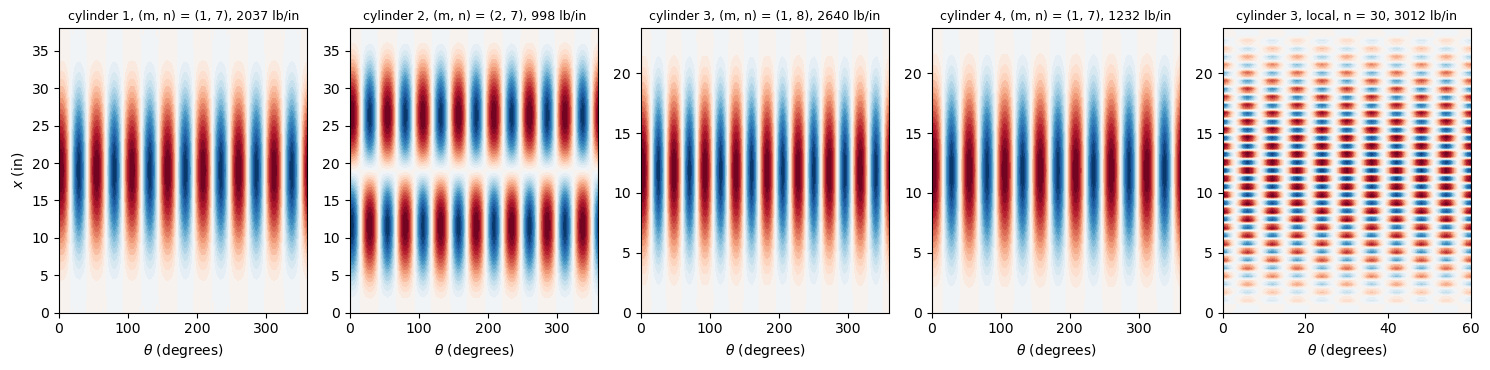

In [13]:
def plot_w(ax, model, mode, n, title):
    w = normalize_phase(model.skin_field(mode, W))
    theta, wfull = model.full_circumference(w, n)
    lim = np.abs(wfull).max()
    ax.contourf(np.degrees(theta), model.xlin, wfull,
                levels=np.linspace(-lim, lim, 31), cmap='RdBu_r')
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(r'$\theta$ (degrees)')


fig, axes = plt.subplots(1, 5, figsize=(15, 3.8))
for ax, k in zip(axes, cylinders):
    model, out = results[(k, 'linear')]
    n, (N, m, mode) = lowest(out)
    plot_w(ax, model, mode, n, 'cylinder %d, (m, n) = (%d, %d), %.0f lb/in'
           % (k, m, n, N))
model, N, m, mode = local[(3, 30)]
plot_w(axes[4], model, mode, 30, 'cylinder 3, local, n = 30, %.0f lb/in' % N)
axes[4].set_xlim(0, 60)
axes[0].set_ylabel('$x$ (in)')
plt.tight_layout()
plt.show()

## Discussion

**Smeared theory of [1].** The smeared-stiffener theory of [2], computed
here with the section of Figure 2(b), reproduces $\bar{N}_c$ and
$\bar{N}_s$ of [1] within 0.7 %. With the pre-buckling state and the end
conditions of this theory, the discrete model reproduces $\bar{N}_c$ within
1 % and $\bar{N}_s$ within 3 % for the four cylinders, is within 0.4 % of
the smeared theory with clamped ends, and gives the ratio of the external
to the internal stiffening. The stiffeners are close (1.00
in) compared with the buckle half-wavelengths of the lowest modes (several
inches around and along the cylinder), so that averaging them over the skin
is accurate for the general instability, and the eccentricity effect, more
than a factor two between external and internal stiffeners, is a property
of the stiffened section that both models represent. The plate stringers
carry their torsional stiffness, which the theory includes as $G_s J_s$;
[1] (report page 11) finds that leaving it out lowers the loads of the
integral cylinders by 10 % to 20 %.

**Pre-buckling state.** With the linear axisymmetric pre-buckling state of
ends that are clamped and kept circular, the critical loads are at most a
few per cent above those of the membrane state: the bending boundary layer
near the ends has little effect on these stiffened cylinders.

**Tests.** The measured buckling loads are 78 % to 92 % of the lowest
critical loads of the model with the idealized test conditions, within the
range that [1] reports against its clamped theory, "70 to 95 percent", and
[1] concludes that "the test cylinders were more nearly clamped than simply
supported". The model is a bifurcation analysis of a perfect cylinder, and
[1] (report page 11) names the contributions to the difference: "neglect of
initial imperfections and ... the absence of an accurate prebuckling
solution in the theory", besides the end conditions. The model does not
include either the two butt joints with their doubler plates or the
fillets; the 4.7 % to 7.4 % of cross-sectional area by which $A_t$ exceeds
the section of Figure 2(b) would lower the ratio of the test loads to the
critical loads to 0.72 to 0.85 (section "Cross-section adjusted to
$A_t$"). The circumferential wave numbers $n_e$ of the
buckled test cylinders are one or two below those of the lowest critical
loads of the model, whose critical load at $n_e$ is higher by 4 % to 21 %.
[1] (report page 8) reports that cylinder 1 buckled in two tiers, two
buckles along the length, while the lowest mode of the model has $m = 1$.

**The panels implementation of this case.** The repository panels models the
same four cylinders with its multidomain assembly (half cylinder,
`cylshell_clpt_sanders` skin, `plate_clpt_gl` blades, Ritz functions). With
the section of Figure 2(b) as used here, a blade plate of height $0.33 -
t/2$ from the middle surface of the skin, it gives with membrane
pre-buckling the clamped loads 2028, 989, 2577 and 1214 lb/in for cylinders
1 to 4 (this model: 2035, 994, 2588, 1219), and the simply supported loads
1136, 664, 1334 and 713 lb/in (this model: 1144, 669, 1350, 723): the two
implementations agree within 0.5 % (clamped) and 1.4 % (simply
supported); the remaining differences come from the end constraints of the
blades (the panels blade end, simply supported, holds only the radial
displacement), the in-plane geometric-stiffness term $N_{xx} U_{,X}^2$ of
the `plate_clpt_gl` blades, which `KG_inplane()` leaves out (0.2 %), and
the discretizations. With the 0.33 in read as the height of the stringer
above the skin, a blade 0.03 in taller, panels gives 2216, 1047, 2885 and
1286 lb/in, 4.9 % to 11.2 % above $\bar{N}_c$, and this model gives the
same offsets (+5.4 % to +11.7 %): the height of the stringer, not the
kinematics of the two codes, explains that difference.
